# 第 3 天：机器学习与 AOI 误报复判

**场景**：AOI 先报警 → 复判模型对**报警样本**二次判断 →
高风险或不确定的送人工复判；低风险的进入"待验证"的自动处理流程。

**目标**：在 AOI 已报警的样本里区分"真实缺陷"和"误报"，同时控制漏检风险。

**本 Notebook 的做法**

1. 用时间切分（并保证同一产品不跨集合）划分训练 / 验证 / 测试
2. 与"只用 AOI 分数"的朴素基线对比，确认模型确实带来增益
3. 演示数据泄漏会怎样高估效果
4. 在验证集选阈值，在测试集评估，给出置信区间
5. 按缺陷类型、按漂移批次检查，记录局限

前置：先运行 `02_aoi_analysis.ipynb` 生成 `data/processed/aoi_clean.csv`。

In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

cwd = Path.cwd()
ROOT = next((folder.parent for folder in (cwd, *cwd.parents) if folder.name == "notebooks"), cwd)
CLEAN = ROOT / "data" / "processed" / "aoi_clean.csv"
DASHBOARD = ROOT / "reports" / "dashboard"
DASHBOARD.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
VALID_START = pd.Timestamp("2026-10-21")
TEST_START = pd.Timestamp("2026-10-26")
TARGET_RECALL = 0.98
GLARE_LINE, GLARE_DAY = "L03", pd.Timestamp("2026-10-27")

NUMERIC = ["aoi_score", "brightness", "contrast"]
CATEGORICAL = ["defect_type"]
FEATURES = NUMERIC + CATEGORICAL


def save(fig, name):
    fig.tight_layout()
    fig.savefig(DASHBOARD / name, dpi=150, bbox_inches="tight")

## 1. 建模数据：只看 AOI 已报警且有参考判定的样本

- 目标 `y = 1` 表示参考判定为真实缺陷，`y = 0` 表示误报
- 特征只用**生产时就能拿到**的信息：AOI 分数、亮度、对比度、AOI 报出的缺陷类型
- **不用**：`reference_result`（就是答案）、`batch_id`/`machine_id`（高基数、无法泛化到新批次新设备）
- 缺失的亮度/对比度在 Pipeline 里用**训练集中位数**填充，避免用全量数据计算预处理参数造成泄漏

In [2]:
clean = pd.read_csv(CLEAN, parse_dates=["inspection_time", "date"])
clean["product_first_date"] = (
    clean.groupby("product_id")["inspection_time"].transform("min").dt.normalize()
)

alarms = clean[clean["is_alarm"] & clean["has_reference"]].copy()
alarms["y"] = alarms["is_actual_defect"].astype(int)
print(f"报警样本 {len(alarms)} 条，其中真实缺陷 {alarms['y'].sum()} 条（{alarms['y'].mean():.1%}）")

报警样本 4689 条，其中真实缺陷 703 条（15.0%）


## 2. 数据划分：时间切分，且同一产品的所有检测事件进同一个集合

按**产品首检日期**切分：复测发生在首检后几分钟，可能跨过午夜，如果直接按每条记录的日期切，
同一产品的首检和复测就会分到不同集合。

In [3]:
split_date = alarms["product_first_date"]
train = alarms[split_date < VALID_START]
valid = alarms[(split_date >= VALID_START) & (split_date < TEST_START)]
test = alarms[split_date >= TEST_START]

overlap = (
    set(train["product_id"]) & set(valid["product_id"])
    | set(train["product_id"]) & set(test["product_id"])
    | set(valid["product_id"]) & set(test["product_id"])
)
assert not overlap, "同一产品出现在多个集合"

pd.DataFrame(
    {
        name: {
            "period": f"{frame['date'].min():%m-%d} ~ {frame['date'].max():%m-%d}",
            "alarms": len(frame),
            "true defects": int(frame["y"].sum()),
            "defect share": f"{frame['y'].mean():.1%}",
        }
        for name, frame in {"train": train, "valid": valid, "test": test}.items()
    }
).T

,period,alarms,true defects,defect share
train,10-01 ~ 10-20,3115,447,14.3%
valid,10-21 ~ 10-25,739,123,16.6%
test,10-26 ~ 10-30,835,133,15.9%


测试期（10-26 之后）包含一个训练期没见过的批次漂移（后面单独检查）。
这模拟了"模型上线后遇到新情况"，是时间切分才能暴露的问题。

## 3. 基线：两个模型 + "只用 AOI 分数"的朴素排序

In [4]:
def build_pipeline(model):
    preprocess = ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
                ),
                NUMERIC,
            ),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ]
    )
    return Pipeline([("preprocess", preprocess), ("model", model)])


def candidate_models():
    return {
        "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "RandomForest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    }


fitted = {}
valid_scores = {}
for name, model in candidate_models().items():
    fitted[name] = build_pipeline(model).fit(train[FEATURES], train["y"])
    valid_scores[name] = fitted[name].predict_proba(valid[FEATURES])[:, 1]
valid_scores["AOI score only (no model)"] = valid["aoi_score"].to_numpy()

baseline_table = pd.DataFrame(
    {
        name: {
            "ROC-AUC": roc_auc_score(valid["y"], score),
            "PR-AUC (avg precision)": average_precision_score(valid["y"], score),
        }
        for name, score in valid_scores.items()
    }
).T
baseline_table.style.format("{:.3f}")

,ROC-AUC,PR-AUC (avg precision)
LogisticRegression,0.955,0.900
RandomForest,0.955,0.895
AOI score only (no model),0.939,0.883


阈值无关的指标看两件事：ROC-AUC 衡量整体排序能力，PR-AUC 在缺陷占比低时更敏感。
**"只用 AOI 分数"这一行是必须击败的基线**：如果复杂模型提升很小，就不值得引入。

In [5]:
best_name = max(
    (n for n in fitted),
    key=lambda n: average_precision_score(valid["y"], valid_scores[n]),
)
best_model = fitted[best_name]
baseline_ap = baseline_table.loc["AOI score only (no model)", "PR-AUC (avg precision)"]
best_ap = baseline_table.loc[best_name, "PR-AUC (avg precision)"]
print(f"按验证集 PR-AUC 选择：{best_name}")
print(
    f"相对「只用 AOI 分数」基线的 PR-AUC 增益：{best_ap - baseline_ap:+.3f}（{baseline_ap:.3f} -> {best_ap:.3f}）"
)

按验证集 PR-AUC 选择：LogisticRegression
相对「只用 AOI 分数」基线的 PR-AUC 增益：+0.017（0.883 -> 0.900）


## 4. 数据泄漏演示：随机切分为什么会"看起来更好"

同一批报警样本，用同一个 RandomForest，只改变切分方式。
复测事件与首检事件的特征几乎相同，随机切分会让模型"见过"测试样本的近亲。

In [6]:
pool = pd.concat([train, valid]).reset_index(drop=True)
N_REPEATS = 8


def evaluate_splits(splits):
    rows = []
    for train_idx, test_idx in splits:
        pipe = build_pipeline(candidate_models()["RandomForest"]).fit(
            pool.iloc[train_idx][FEATURES], pool.iloc[train_idx]["y"]
        )
        proba = pipe.predict_proba(pool.iloc[test_idx][FEATURES])[:, 1]
        y = pool.iloc[test_idx]["y"]
        rows.append(
            {
                "ROC-AUC": roc_auc_score(y, proba),
                "PR-AUC": average_precision_score(y, proba),
            }
        )
    frame = pd.DataFrame(rows)
    return {
        "ROC-AUC (mean)": frame["ROC-AUC"].mean(),
        "PR-AUC (mean)": frame["PR-AUC"].mean(),
        "PR-AUC (std)": frame["PR-AUC"].std(),
    }


row_splits = StratifiedShuffleSplit(
    n_splits=N_REPEATS, test_size=0.3, random_state=RANDOM_STATE
).split(pool, pool["y"])
group_splits = GroupShuffleSplit(
    n_splits=N_REPEATS, test_size=0.3, random_state=RANDOM_STATE
).split(pool, groups=pool["product_id"])

leak_table = pd.DataFrame(
    {
        "Random split by row (leaky)": evaluate_splits(row_splits),
        "Random split grouped by product_id": evaluate_splits(group_splits),
    }
).T
leak_table.style.format("{:.3f}")

,ROC-AUC (mean),PR-AUC (mean),PR-AUC (std)
Random split by row (leaky),0.953,0.872,0.018
Random split grouped by product_id,0.945,0.854,0.018


两种切分用的是**同一个数据池、同一个模型、各重复 8 次取平均**，唯一区别是
同一产品的首检和复测会不会被拆到训练集和测试集两边。

In [7]:
leak_gap = (
    leak_table.loc["Random split by row (leaky)", "PR-AUC (mean)"]
    - leak_table.loc["Random split grouped by product_id", "PR-AUC (mean)"]
)
retest_share = 1 - pool["product_id"].nunique() / len(pool)
display(
    Markdown(
        textwrap.dedent(
            f"""
            逐行随机切分的 PR-AUC 比按产品分组切分高 **{leak_gap:+.3f}**，这部分是复测样本泄漏带来的虚高。

            **要如实解读幅度**：这里复测样本只占 {retest_share:.0%}，特征只有 3 个表格数值，模型容量也有限，
            所以虚高幅度不大。如果是图像任务（同一工件多张几乎一样的照片、重复比例更高），
            虚高会严重得多。**结论：模型评估必须按产品分组（或按时间）切分。**
            """
        )
    )
)


逐行随机切分的 PR-AUC 比按产品分组切分高 **+0.017**，这部分是复测样本泄漏带来的虚高。

**要如实解读幅度**：这里复测样本只占 16%，特征只有 3 个表格数值，模型容量也有限，
所以虚高幅度不大。如果是图像任务（同一工件多张几乎一样的照片、重复比例更高），
虚高会严重得多。**结论：模型评估必须按产品分组（或按时间）切分。**


## 5. 阈值：在验证集选择，在测试集评估

模型输出"该报警是真实缺陷的概率" `p`。策略：`p < 阈值` 的报警自动放行（待验证），其余送人工复判。

质量约束优先：**先确定可接受的漏检风险，再看能省多少人工**。这里设定目标：
验证集上，报警中的真实缺陷被保留（送人工）的比例 ≥ 98%。

In [8]:
def sweep(y, proba, thresholds):
    rows = []
    for t in thresholds:
        review = proba >= t
        caught = int((review & (y == 1)).sum())
        missed = int((~review & (y == 1)).sum())
        rows.append(
            {
                "threshold": t,
                "to_review": int(review.sum()),
                "auto_released": int((~review).sum()),
                "defects_caught": caught,
                "defects_missed": missed,
                "recall": caught / max(caught + missed, 1),
                "workload_reduction": 1 - review.mean(),
                "false_positives_released": int((~review & (y == 0)).sum()),
            }
        )
    return pd.DataFrame(rows)


grid = np.round(np.arange(0.01, 0.99, 0.01), 2)
valid_proba = valid_scores[best_name]
valid_sweep = sweep(valid["y"].to_numpy(), valid_proba, grid)

eligible = valid_sweep[valid_sweep["recall"] >= TARGET_RECALL]
chosen_threshold = float(eligible["threshold"].max())
print(f"验证集上满足 Recall >= {TARGET_RECALL:.0%} 的最大阈值：{chosen_threshold}")

display_grid = sorted({0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, chosen_threshold})
sweep_fmt = {"recall": "{:.1%}", "workload_reduction": "{:.1%}"}
valid_sweep[valid_sweep["threshold"].isin(display_grid)].style.format(sweep_fmt)

验证集上满足 Recall >= 98% 的最大阈值：0.05


,threshold,to_review,auto_released,defects_caught,defects_missed,recall,workload_reduction,false_positives_released
4,0.050000,489,250,121,2,98.4%,33.8%,248
9,0.100000,368,371,119,4,96.7%,50.2%,367
19,0.200000,278,461,117,6,95.1%,62.4%,455
29,0.300000,233,506,113,10,91.9%,68.5%,496
39,0.400000,201,538,113,10,91.9%,72.8%,528
49,0.500000,173,566,110,13,89.4%,76.6%,553
59,0.600000,155,584,109,14,88.6%,79.0%,570
69,0.700000,134,605,107,16,87.0%,81.9%,589
79,0.800000,119,620,101,22,82.1%,83.9%,598


阈值越高，自动放行越多，人工量越小，但漏掉的真实缺陷也越多。
把**阈值固定为验证集选出的值**，再在从未参与调参的测试集上评估：

In [9]:
test_proba = best_model.predict_proba(test[FEATURES])[:, 1]
test_sweep = sweep(test["y"].to_numpy(), test_proba, grid)
test_row = test_sweep[test_sweep["threshold"] == chosen_threshold].iloc[0]

defects_total = int(test_row["defects_caught"] + test_row["defects_missed"])
recall_ci = stats.binomtest(int(test_row["defects_caught"]), defects_total).proportion_ci(
    confidence_level=0.95, method="exact"
)
fp_total = int((test["y"] == 0).sum())
fp_released = int(test_row["false_positives_released"])

print(f"测试集，阈值 {chosen_threshold}")
print(
    f"  报警 {len(test)} 条，自动放行 {int(test_row['auto_released'])} 条，送人工 {int(test_row['to_review'])} 条"
)
print(f"  人工复判量下降 {test_row['workload_reduction']:.1%}")
print(
    f"  报警中的真实缺陷 {defects_total} 条，保留 {int(test_row['defects_caught'])} 条，漏掉 {int(test_row['defects_missed'])} 条"
)
print(
    f"  Recall {test_row['recall']:.1%}（95% 置信区间 {recall_ci.low:.1%} ~ {recall_ci.high:.1%}）"
)
print(f"  误报 {fp_total} 条，其中被自动放行 {fp_released} 条（{fp_released / fp_total:.1%}）")

测试集，阈值 0.05
  报警 835 条，自动放行 278 条，送人工 557 条
  人工复判量下降 33.3%
  报警中的真实缺陷 133 条，保留 131 条，漏掉 2 条
  Recall 98.5%（95% 置信区间 94.7% ~ 99.8%）
  误报 702 条，其中被自动放行 276 条（39.3%）


In [10]:
test_sweep[test_sweep["threshold"].isin(display_grid)].style.format(sweep_fmt)

,threshold,to_review,auto_released,defects_caught,defects_missed,recall,workload_reduction,false_positives_released
4,0.050000,557,278,131,2,98.5%,33.3%,276
9,0.100000,416,419,129,4,97.0%,50.2%,415
19,0.200000,295,540,127,6,95.5%,64.7%,534
29,0.300000,216,619,123,10,92.5%,74.1%,609
39,0.400000,187,648,119,14,89.5%,77.6%,634
49,0.500000,166,669,116,17,87.2%,80.1%,652
59,0.600000,145,690,114,19,85.7%,82.6%,671
69,0.700000,131,704,110,23,82.7%,84.3%,681
79,0.800000,103,732,97,36,72.9%,87.7%,696


注意置信区间：测试集真实缺陷只有一百条左右，Recall 的区间很宽。
**一个点估计不足以支撑"可以放行"的决定**，需要更多样本和产线试运行。

### 混淆矩阵（测试集，阈值固定）

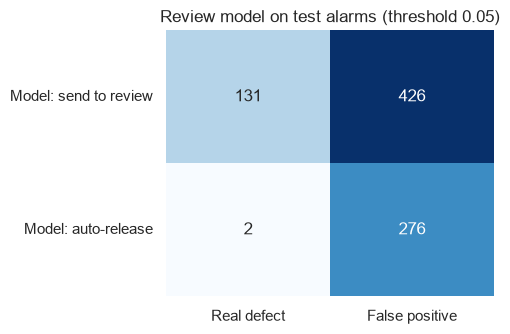

In [11]:
review_flag = test_proba >= chosen_threshold
cm = pd.DataFrame(
    [
        [int((review_flag & (test["y"] == 1)).sum()), int((review_flag & (test["y"] == 0)).sum())],
        [
            int((~review_flag & (test["y"] == 1)).sum()),
            int((~review_flag & (test["y"] == 0)).sum()),
        ],
    ],
    index=["Model: send to review", "Model: auto-release"],
    columns=["Real defect", "False positive"],
)
fig, ax = plt.subplots(figsize=(5.2, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"Review model on test alarms (threshold {chosen_threshold})")
save(fig, "08_review_model_confusion.png")

### PR 曲线与阈值权衡图

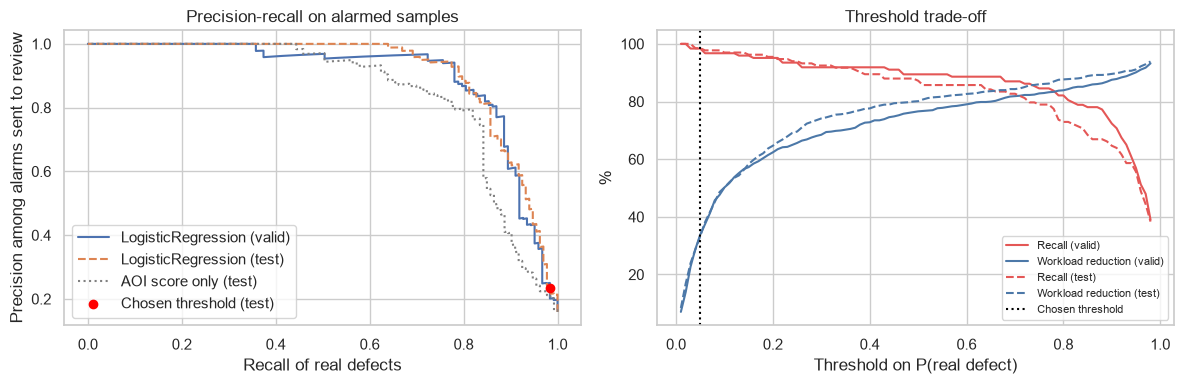

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, frame, proba, style in [
    ("valid", valid, valid_proba, "-"),
    ("test", test, test_proba, "--"),
]:
    precision, recall, _ = precision_recall_curve(frame["y"], proba)
    axes[0].plot(recall, precision, style, label=f"{best_name} ({label})")
precision, recall, _ = precision_recall_curve(test["y"], test["aoi_score"])
axes[0].plot(recall, precision, ":", color="gray", label="AOI score only (test)")
axes[0].scatter(
    [test_row["recall"]],
    [test_row["defects_caught"] / test_row["to_review"]],
    color="red",
    zorder=5,
    label="Chosen threshold (test)",
)
axes[0].set_xlabel("Recall of real defects")
axes[0].set_ylabel("Precision among alarms sent to review")
axes[0].set_title("Precision-recall on alarmed samples")
axes[0].legend()

for label, sweep_df, style in [("valid", valid_sweep, "-"), ("test", test_sweep, "--")]:
    axes[1].plot(
        sweep_df["threshold"],
        sweep_df["recall"] * 100,
        style,
        color="#E45756",
        label=f"Recall ({label})",
    )
    axes[1].plot(
        sweep_df["threshold"],
        sweep_df["workload_reduction"] * 100,
        style,
        color="#4C78A8",
        label=f"Workload reduction ({label})",
    )
axes[1].axvline(chosen_threshold, color="black", linestyle=":", label="Chosen threshold")
axes[1].set_xlabel("Threshold on P(real defect)")
axes[1].set_ylabel("%")
axes[1].set_title("Threshold trade-off")
axes[1].legend(fontsize=8)
save(fig, "09_pr_curve_and_threshold_tradeoff.png")

## 6. 按缺陷类型检查（测试集真实缺陷）

整体 Recall 达标不代表每类都达标，尤其是严重缺陷。

In [13]:
test_eval = test.assign(proba=test_proba, released=test_proba < chosen_threshold)
defect_rows = test_eval[test_eval["y"] == 1]
by_type = (
    defect_rows.groupby("defect_type")
    .agg(defects=("y", "size"), missed=("released", "sum"))
    .assign(recall=lambda t: 1 - t["missed"] / t["defects"])
)
by_type.style.format({"recall": "{:.1%}"})

,defects,missed,recall
defect_type,,,
crack,25,0,100.0%
dent,32,0,100.0%
scratch,63,2,96.8%
stain,13,0,100.0%


每类样本量很小，一次漏检就会让该类 Recall 大幅波动，**不能据此断言某类"没问题"或"有问题"**，
只能说明需要为高风险缺陷类型积累更多样本，或者对它们采用更保守的阈值/始终人工复判。

## 7. 漂移检查：训练期没见过的反光批次

In [14]:
glare_mask = (test_eval["line_id"] == GLARE_LINE) & (test_eval["date"] == GLARE_DAY)


def drift_row(frame):
    fp = frame[frame["y"] == 0]
    defects = frame[frame["y"] == 1]
    return {
        "alarms": len(frame),
        "false positives": len(fp),
        "FP auto-released": fp["released"].mean(),
        "real defects": len(defects),
        "defects missed": int(defects["released"].sum()),
        "mean brightness": frame["brightness"].mean(),
        "mean contrast": frame["contrast"].mean(),
    }


drift_table = pd.DataFrame(
    {
        "glare": drift_row(test_eval[glare_mask]),
        "rest": drift_row(test_eval[~glare_mask]),
    }
).T
display(
    drift_table.rename(
        index={
            "glare": f"Glare batch ({GLARE_LINE}, {GLARE_DAY:%m-%d})",
            "rest": "Rest of test period",
        }
    ).style.format(
        {
            "alarms": "{:.0f}",
            "false positives": "{:.0f}",
            "FP auto-released": "{:.1%}",
            "real defects": "{:.0f}",
            "defects missed": "{:.0f}",
            "mean brightness": "{:.1f}",
            "mean contrast": "{:.1f}",
        }
    )
)

glare, rest = drift_table.loc["glare"], drift_table.loc["rest"]
display(
    Markdown(
        textwrap.dedent(
            f"""
            漂移批次的亮度偏高（{glare["mean brightness"]:.0f} vs {rest["mean brightness"]:.0f}）、
            对比度偏低（{glare["mean contrast"]:.1f} vs {rest["mean contrast"]:.1f}），和训练期分布不同。
            模型对误报的自动放行比例从 {rest["FP auto-released"]:.0%} 变成 {glare["FP auto-released"]:.0%}，
            该批次 {int(glare["real defects"])} 个真实缺陷中漏放 {int(glare["defects missed"])} 个。

            样本太少，不能据此估计漂移下的真实漏检率；但**放行比例在某个批次突然变化，本身就是必须监控的信号**。
            上线后要监控输入分布和放行比例，出现漂移时回退到全部人工复判，直到重新验证。
            """
        )
    )
)

,alarms,false positives,FP auto-released,real defects,defects missed,mean brightness,mean contrast
"Glare batch (L03, 10-27)",102,99,59.6%,3,1,134.9,18.4
Rest of test period,733,603,36.0%,130,1,124.8,23.4



漂移批次的亮度偏高（135 vs 125）、
对比度偏低（18.4 vs 23.4），和训练期分布不同。
模型对误报的自动放行比例从 36% 变成 60%，
该批次 3 个真实缺陷中漏放 1 个。

样本太少，不能据此估计漂移下的真实漏检率；但**放行比例在某个批次突然变化，本身就是必须监控的信号**。
上线后要监控输入分布和放行比例，出现漂移时回退到全部人工复判，直到重新验证。


## 8. 系统层面：AOI 漏检 + 模型漏检会叠加

复判模型只看 AOI **已经报警**的样本，AOI 本身漏掉的缺陷它救不回来。
所以端到端的真实缺陷保留率 = (AOI 检出且被模型保留的缺陷) / 全部真实缺陷。
这里只用每件产品的**首检**，避免复测重复计数。

In [15]:
test_first = test_eval[test_eval["is_first_pass"]]
all_first_test = clean[
    clean["is_first_pass"] & clean["has_reference"] & (clean["product_first_date"] >= TEST_START)
]
defects_all = int(all_first_test["is_actual_defect"].sum())
aoi_caught = int(test_first["y"].sum())
model_missed_first = int(test_first[test_first["y"] == 1]["released"].sum())
end_to_end = (aoi_caught - model_missed_first) / defects_all

print(f"测试期真实缺陷（首检）{defects_all} 件")
print(f"  AOI 漏检 {defects_all - aoi_caught} 件（AOI 本身 Recall {aoi_caught / defects_all:.1%}）")
print(f"  复判模型额外漏放 {model_missed_first} 件")
print(f"  端到端缺陷保留率 {end_to_end:.1%}")

测试期真实缺陷（首检）106 件
  AOI 漏检 3 件（AOI 本身 Recall 97.2%）
  复判模型额外漏放 2 件
  端到端缺陷保留率 95.3%


## 9. 保存指标，供面试笔记引用

In [16]:
metrics = {
    "model": best_name,
    "features": FEATURES,
    "target_recall_on_valid": TARGET_RECALL,
    "chosen_threshold": chosen_threshold,
    "validation_pr_auc": float(average_precision_score(valid["y"], valid_proba)),
    "validation_pr_auc_aoi_score_only": float(
        average_precision_score(valid["y"], valid["aoi_score"])
    ),
    "test": {
        "alarms": len(test),
        "to_review": int(test_row["to_review"]),
        "auto_released": int(test_row["auto_released"]),
        "workload_reduction": float(test_row["workload_reduction"]),
        "defects": defects_total,
        "defects_missed": int(test_row["defects_missed"]),
        "recall": float(test_row["recall"]),
        "recall_ci95": [float(recall_ci.low), float(recall_ci.high)],
        "false_positives": fp_total,
        "false_positives_released": fp_released,
        "end_to_end_defect_retention": float(end_to_end),
        "aoi_recall_first_pass": float(aoi_caught / defects_all),
    },
    "leakage_demo_pr_auc_mean": {k: float(v) for k, v in leak_table["PR-AUC (mean)"].items()},
}
(ROOT / "data" / "processed" / "model_metrics.json").write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False)
)
display(Markdown(f"```json\n{json.dumps(metrics, indent=2, ensure_ascii=False)}\n```"))

```json
{
  "model": "LogisticRegression",
  "features": [
    "aoi_score",
    "brightness",
    "contrast",
    "defect_type"
  ],
  "target_recall_on_valid": 0.98,
  "chosen_threshold": 0.05,
  "validation_pr_auc": 0.8999790352831272,
  "validation_pr_auc_aoi_score_only": 0.8826381778647818,
  "test": {
    "alarms": 835,
    "to_review": 557,
    "auto_released": 278,
    "workload_reduction": 0.332934131736527,
    "defects": 133,
    "defects_missed": 2,
    "recall": 0.9849624060150376,
    "recall_ci95": [
      0.9467356013821775,
      0.9981736611688586
    ],
    "false_positives": 702,
    "false_positives_released": 276,
    "end_to_end_defect_retention": 0.9528301886792453,
    "aoi_recall_first_pass": 0.9716981132075472
  },
  "leakage_demo_pr_auc_mean": {
    "Random split by row (leaky)": 0.8715180611263172,
    "Random split grouped by product_id": 0.8543525836431837
  }
}
```

## 10. 局限性（当日交付物：数据划分和样本来源的限制）

- **模拟数据**：特征与标签的关系是我设定的，真实产线的难度、噪声和漂移形态会不同；
  结果只能证明练习过程，不能证明模型适用于任何真实产线。
- **每条记录都有参考判定**：真实产线通常只有报警件被复判，很难得到无偏的漏检评估，需要独立抽检。
- **样本量小**：测试集真实缺陷约一百条，Recall 的置信区间很宽；分缺陷类型后更小。
- **标签质量**：这里的参考判定被默认为真值；真实场景中人工复判本身有分歧，需要先做标注一致性评估。
- **漂移**：测试期里的新批次分布与训练期不同，模型行为未经验证；需要监控和回退机制。
- **只是二次判断**：模型无法修复 AOI 自身的漏检，端到端风险是两层叠加。
- **决策层面**：自动放行是"待验证的流程"，必须经过影子运行和小范围试点，不能直接上线。